In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

print("project environment is ready!")

project environment is ready!


In [6]:
from pathlib import Path

print("Python is working in:")
print(Path.cwd())

raw_folder = Path("../data/raw")

print("\nDoes the expected raw folder exist?")
print(raw_folder.exists())

if raw_folder.exists():
    print("\nFiles inside raw:")
    for file in raw_folder.iterdir():
        print(file.name)

Python is working in:
C:\Users\harsh\OneDrive\Documents\Hospital_quality_analysis\notebooks

Does the expected raw folder exist?
True

Files inside raw:
.ipynb_checkpoints
Hospital_General_Information.csv.csv


In [7]:
df = pd.read_csv(
    "../data/raw/hospital_general_information.csv",
    dtype=str
)

df.head()

,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Hospital Type,Hospital Ownership,...,Count of READM Measures Better,Count of READM Measures No Different,Count of READM Measures Worse,READM Group Footnote,Pt Exp Group Measure Count,Count of Facility Pt Exp Measures,Pt Exp Group Footnote,TE Group Measure Count,Count of Facility TE Measures,TE Group Footnote
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,Acute Care Hospitals,Government - Hospital District or Authority,...,1,9,1,NaN,15,15,NaN,10,10,NaN
1,010005,MARSHALL MEDICAL CENTERS,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,MARSHALL,(256) 593-8310,Acute Care Hospitals,Government - Hospital District or Authority,...,1,8,0,NaN,15,15,NaN,10,10,NaN
2,010006,NORTH ALABAMA MEDICAL CENTER,1701 VETERANS DRIVE,FLORENCE,AL,35630,LAUDERDALE,(256) 768-8400,Acute Care Hospitals,Proprietary,...,1,8,0,NaN,15,15,NaN,10,9,NaN
3,010007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,OPP,AL,36467,COVINGTON,(334) 493-3541,Acute Care Hospitals,Voluntary non-profit - Private,...,0,3,2,NaN,15,5,NaN,10,7,NaN
4,010011,ST. VINCENT'S EAST,50 MEDICAL PARK EAST DRIVE,BIRMINGHAM,AL,35235,JEFFERSON,(205) 838-3122,Acute Care Hospitals,Voluntary non-profit - Private,...,1,5,2,29,15,10,29,10,7,29


In [10]:
# Count the rows and columns
print("Number of hospital records:", df.shape[0])
print("Number of columns:", df.shape[1])

# Show the column names
print("\nColumn names:")
for column in df.columns:
    print(column)

Number of hospital records: 5419
Number of columns: 38

Column names:
Facility ID
Facility Name
Address
City/Town
State
ZIP Code
County/Parish
Telephone Number
Hospital Type
Hospital Ownership
Emergency Services
Meets criteria for birthing friendly designation
Hospital overall rating
Hospital overall rating footnote
MORT Group Measure Count
Count of Facility MORT Measures
Count of MORT Measures Better
Count of MORT Measures No Different
Count of MORT Measures Worse
MORT Group Footnote
Safety Group Measure Count
Count of Facility Safety Measures
Count of Safety Measures Better
Count of Safety Measures No Different
Count of Safety Measures Worse
Safety Group Footnote
READM Group Measure Count
Count of Facility READM Measures
Count of READM Measures Better
Count of READM Measures No Different
Count of READM Measures Worse
READM Group Footnote
Pt Exp Group Measure Count
Count of Facility Pt Exp Measures
Pt Exp Group Footnote
TE Group Measure Count
Count of Facility TE Measures
TE Group Foo

In [11]:
# Count completely identical rows
print("Duplicate rows:", df.duplicated().sum())

# Check whether hospital IDs repeat
print("Repeated hospital IDs:", df["Facility ID"].duplicated().sum())

# Show every rating value and its number of records
print("\nHospital rating values:")
print(df["Hospital overall rating"].value_counts(dropna=False))

Duplicate rows: 0
Repeated hospital IDs: 0

Hospital rating values:
Hospital overall rating
Not Available    2245
3                 985
4                 946
2                 661
5                 384
1                 198
Name: count, dtype: int64


In [12]:
# Keep the original table and make a copy for cleaning
df_clean = df.copy()

# Convert ratings to numbers; nonnumeric text becomes missing
df_clean["Hospital overall rating"] = pd.to_numeric(
    df_clean["Hospital overall rating"],
    errors="coerce"
)

# Check the result
print("Hospitals with a rating:",
      df_clean["Hospital overall rating"].notna().sum())

print("Hospitals without a rating:",
      df_clean["Hospital overall rating"].isna().sum())

Hospitals with a rating: 3174
Hospitals without a rating: 2245


In [13]:
# Inspect hospital types, ownership, and emergency services
for column in ["Hospital Type", "Hospital Ownership", "Emergency Services"]:
    print(f"\n{column}:")
    print(df_clean[column].value_counts(dropna=False))


Hospital Type:
Hospital Type
Acute Care Hospitals                    3107
Critical Access Hospitals               1382
Psychiatric                              624
Acute Care - Veterans Administration     132
Childrens                                 94
Rural Emergency Hospital                  43
Acute Care - Department of Defense        32
Long-term                                  5
Name: count, dtype: int64

Hospital Ownership:
Hospital Ownership
Voluntary non-profit - Private                 2322
Proprietary                                    1063
Government - Hospital District or Authority     512
Government - Local                              393
Voluntary non-profit - Other                    353
Voluntary non-profit - Church                   264
Government - State                              209
Veterans Health Administration                  132
Physician                                        80
Government - Federal                             42
Department of Defense   

In [14]:
# Summarize rating availability for each hospital type
type_summary = df_clean.groupby("Hospital Type").agg(
    total_hospitals=("Facility ID", "size"),
    rated_hospitals=("Hospital overall rating", "count")
)

# Calculate the percentage with an available rating
type_summary["rated_percent"] = (
    type_summary["rated_hospitals"]
    / type_summary["total_hospitals"] * 100
).round(1)

type_summary

,total_hospitals,rated_hospitals,rated_percent
Hospital Type,,,
Acute Care - Department of Defense,32,0,0.0
Acute Care - Veterans Administration,132,112,84.8
Acute Care Hospitals,3107,2663,85.7
Childrens,94,0,0.0
Critical Access Hospitals,1382,399,28.9
Long-term,5,0,0.0
Psychiatric,624,0,0.0
Rural Emergency Hospital,43,0,0.0


In [15]:
# Add the average available rating to our summary
type_summary["average_rating"] = (
    df_clean.groupby("Hospital Type")["Hospital overall rating"]
    .mean()
    .round(2)
)

type_summary

,total_hospitals,rated_hospitals,rated_percent,average_rating
Hospital Type,,,,
Acute Care - Department of Defense,32,0,0.0,NaN
Acute Care - Veterans Administration,132,112,84.8,4.16
Acute Care Hospitals,3107,2663,85.7,3.16
Childrens,94,0,0.0,NaN
Critical Access Hospitals,1382,399,28.9,3.22
Long-term,5,0,0.0,NaN
Psychiatric,624,0,0.0,NaN
Rural Emergency Hospital,43,0,0.0,NaN


In [16]:
# Select the ratings that are available
ratings = df_clean["Hospital overall rating"].dropna()

# Find values outside the expected whole-number ratings
invalid_ratings = ratings[~ratings.isin([1, 2, 3, 4, 5])]

print("Invalid ratings:", len(invalid_ratings))
print("\nRating counts:")
print(ratings.value_counts().sort_index())

Invalid ratings: 0

Rating counts:
Hospital overall rating
1.0    198
2.0    661
3.0    985
4.0    946
5.0    384
Name: count, dtype: int64


In [17]:
# Check important identifying and location columns
columns_to_check = [
    "Facility ID",
    "Facility Name",
    "State",
    "City/Town",
    "ZIP Code"
]

for column in columns_to_check:
    values = df_clean[column]

    # Count missing values and text containing only spaces
    missing_or_blank = (
        values.isna() | values.fillna("").str.strip().eq("")
    )

    print(f"{column}: {missing_or_blank.sum()} missing or blank")

Facility ID: 0 missing or blank
Facility Name: 0 missing or blank
State: 0 missing or blank
City/Town: 0 missing or blank
ZIP Code: 0 missing or blank


In [18]:
# Select text columns
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

# Remove leading and trailing spaces
for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

print("Text cleanup completed.")
print("Hospital records:", len(df_clean))

Text cleanup completed.
Hospital records: 5419


In [19]:
# Label each hospital by rating availability
df_clean["Rating Status"] = (
    df_clean["Hospital overall rating"].notna()
    .map({True: "Rated", False: "Not Rated"})
)

# Check the counts
print(df_clean["Rating Status"].value_counts())

Rating Status
Rated        3174
Not Rated    2245
Name: count, dtype: int64


In [20]:
# Summarize hospitals in each state
state_summary = df_clean.groupby("State").agg(
    total_hospitals=("Facility ID", "size"),
    rated_hospitals=("Hospital overall rating", "count"),
    average_rating=("Hospital overall rating", "mean")
)

# Calculate rating coverage
state_summary["rated_percent"] = (
    state_summary["rated_hospitals"]
    / state_summary["total_hospitals"] * 100
)

# Round values and display the first ten state codes
state_summary = state_summary.round({
    "average_rating": 2,
    "rated_percent": 1
})

state_summary.head(10)

,total_hospitals,rated_hospitals,average_rating,rated_percent
State,,,,
AK,25,10,2.90,40.0
AL,99,58,2.74,58.6
AR,90,43,2.86,47.8
AS,1,0,NaN,0.0
AZ,108,55,3.11,50.9
CA,377,279,3.10,74.0
CO,96,49,3.96,51.0
CT,36,26,3.42,72.2
DC,10,7,2.86,70.0


In [21]:
# Display the Texas summary
state_summary.loc[["TX"]]

,total_hospitals,rated_hospitals,average_rating,rated_percent
State,,,,
TX,467,216,3.38,46.3


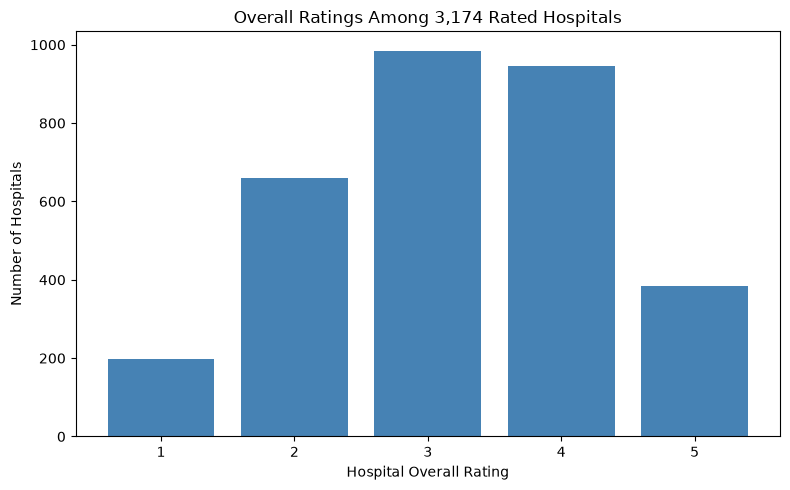

In [22]:
# Count available ratings and put them in order
rating_counts = (
    df_clean["Hospital overall rating"]
    .value_counts()
    .sort_index()
)

# Create a bar chart
plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values, color="steelblue")

plt.title("Overall Ratings Among 3,174 Rated Hospitals")
plt.xlabel("Hospital Overall Rating")
plt.ylabel("Number of Hospitals")
plt.xticks([1, 2, 3, 4, 5])

plt.tight_layout()
plt.show()

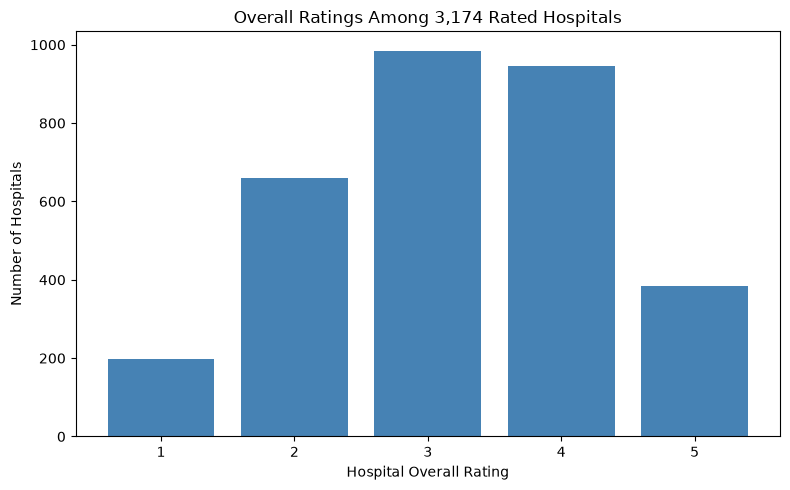

Chart saved successfully.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Reload the hospital dataset
df_clean = pd.read_csv(
    "../data/raw/hospital_general_information.csv",
    dtype=str
)

# Convert the rating column to numbers
df_clean["Hospital overall rating"] = pd.to_numeric(
    df_clean["Hospital overall rating"],
    errors="coerce"
)

# Count hospitals for each available rating
rating_counts = (
    df_clean["Hospital overall rating"]
    .value_counts()
    .sort_index()
)

# Create the graph
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    rating_counts.index,
    rating_counts.values,
    color="steelblue"
)

ax.set_title("Overall Ratings Among 3,174 Rated Hospitals")
ax.set_xlabel("Hospital Overall Rating")
ax.set_ylabel("Number of Hospitals")
ax.set_xticks([1, 2, 3, 4, 5])

fig.tight_layout()

# Save the completed graph
fig.savefig(
    "../images/hospital_rating_distribution_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully.")

In [4]:
# Save the cleaned hospital dataset
df_clean.to_csv(
    "../data/processed/hospital_quality_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")
print("Rows saved:", len(df_clean))
print("Columns saved:", len(df_clean.columns))

Cleaned dataset saved successfully.
Rows saved: 5419
Columns saved: 38


In [5]:
# Remove extra spaces from all text columns
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

# Add a clear rating-availability column
df_clean["Rating Status"] = (
    df_clean["Hospital overall rating"]
    .notna()
    .map({True: "Rated", False: "Not Rated"})
)

# Save the final cleaned dataset
df_clean.to_csv(
    "../data/processed/hospital_quality_cleaned.csv",
    index=False
)

print("Final cleaned dataset saved successfully.")
print("Rows saved:", len(df_clean))
print("Columns saved:", len(df_clean.columns))
print("\nRating status:")
print(df_clean["Rating Status"].value_counts())

Final cleaned dataset saved successfully.
Rows saved: 5419
Columns saved: 39

Rating status:
Rating Status
Rated        3174
Not Rated    2245
Name: count, dtype: int64
